In [2]:
import sys
import os
import numpy as np
import pandas as pd
import pickle
import h5py
from matplotlib import pyplot as plt
import seaborn as sns

sys.path.append(os.path.join(os.getcwd(), '../'))
from utils import read_utils

In [3]:
import importlib
importlib.reload(read_utils)

<module 'utils.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/data_exploration/../utils/read_utils.py'>

In [4]:
path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffer')

names = [
	'2019_07_01_fly2',
	'2019_08_14_fly1',
	'2019_10_10_fly3',
	'2019_10_21_fly1',
	'2019_08_14_fly3_2',
	'2019_10_14_fly3',
	'2019_10_14_fly4',
	'2019_10_18_fly3',
	'2019_06_28_fly2',
	'2019_08_14_fly2',
	'2019_08_07_fly2',
	'2019_10_02_fly2',
	'2019_08_20_fly3',
	'2019_08_20_fly2',
	'2019_10_14_fly2',
	'2019_10_18_fly2',
	'2018_08_24_fly3_run1',
	'2018_08_24_fly2_run2',
]
# names = [name.split('.')[0] for name in os.listdir(os.path.join(path, 'nwb_all'))]

In [5]:
# datas_nwb = list()
# datas_pickle = list()
#
# for name in names:
#
# 	data_nwb = dict()
# 	def load(_name, object):
# 		# print(name)
# 		if isinstance(object, h5py.Dataset):
# 			data_nwb[_name] = object[()]
#
# 	with h5py.File(os.path.join(path, 'nwb_all', f'{name}.nwb'), 'r') as file_handle:
# 		file_handle.visititems(load)
#
# 	datas_nwb.append(data_nwb)
#
#
# 	# with open(os.path.join(path, 'pickle', f'{name}_dict.pkl'), 'rb') as file:
# 	# 	data_pickle = pickle.load(file)
# 	#
# 	# # for key in data_pickle.keys():
# 	# # 	print(key)
# 	#
# 	# datas_pickle.append(data_pickle)

In [6]:
traces = list()

for name in names:

	data_nwb = dict()
	def load(_name, object):
		# print(name)
		if isinstance(object, h5py.Dataset) and _name in ('processing/ophys/DfOverF/RoiResponseSeries/data',
														  'processing/ophys/DfOverF/RoiResponseSeries/timestamps'):
			data_nwb[_name] = object[()]

	with h5py.File(os.path.join(path, 'nwb_all', f'{name}.nwb'), 'r') as file_handle:
		file_handle.visititems(load)

	traces.append(data_nwb)

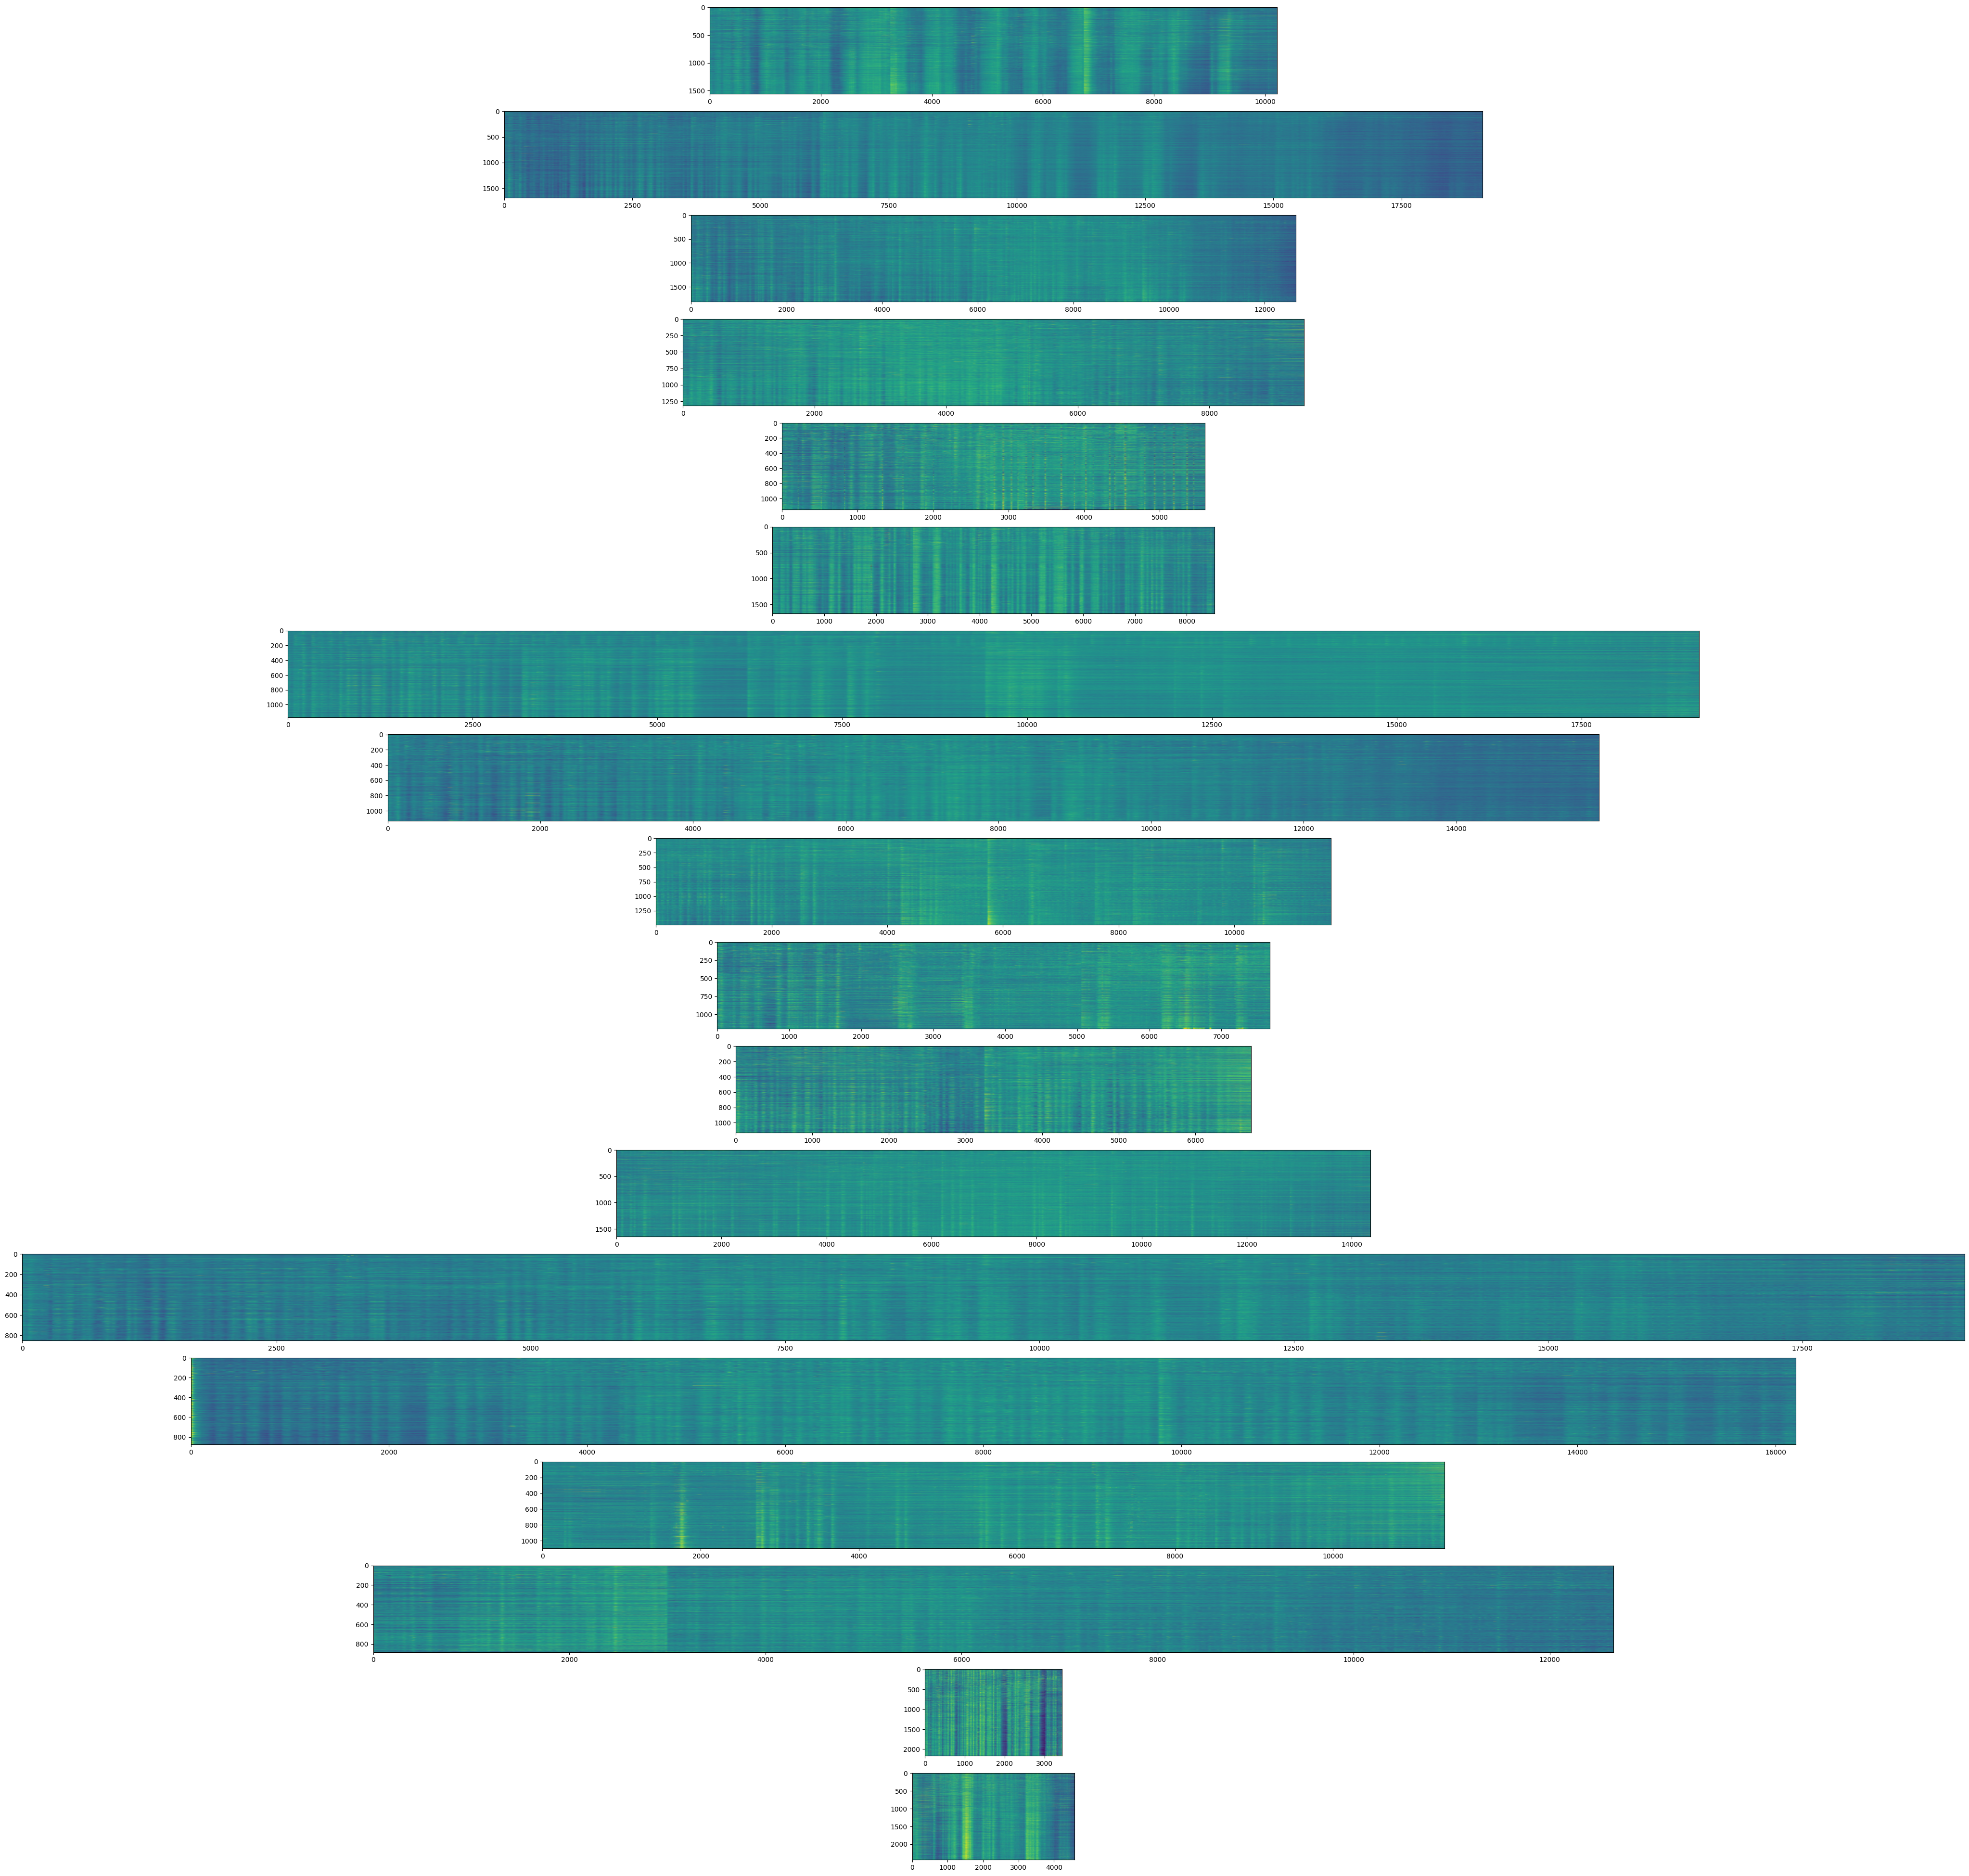

In [9]:
fig, axis = plt.subplots(18, 1, figsize=(100, 50), squeeze=False)

for i, trace in enumerate(traces):
	axis[i, 0].imshow(np.clip(trace['processing/ophys/DfOverF/RoiResponseSeries/data'], -0.05, 0.05).T)

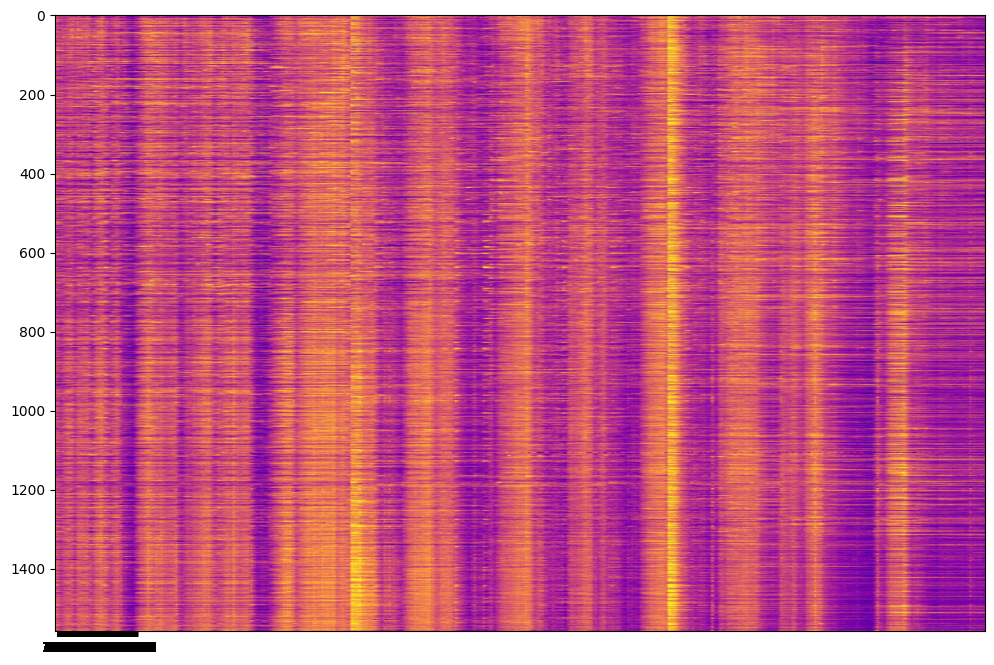

In [40]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(np.clip(traces[0]['processing/ophys/DfOverF/RoiResponseSeries/data'], -0.03, 0.03).T, aspect='auto', cmap='plasma')
plt.xticks(traces[0]['processing/ophys/DfOverF/RoiResponseSeries/timestamps'])
plt.show()